# EN3160 – Assignment 2: Fitting and Alignment

**Name:** Ransara Maldeniya  |  **Index No:** 230390A  |  **GitHub:** https://github.com/ransara3/EN3160-Assignment-2-Fitting-and-Alignment.git



In [3]:
import glob, os
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import minimize

plt.rcParams["figure.dpi"] = 110
def show(img_bgr, title="", figsize=(9, 6)):
    plt.figure(figsize=figsize); plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

---
# Q1 – Blob detection with LoG and scale-space extrema

**Theory.** A blob of radius $r$ gives a maximum response to a Laplacian of Gaussian (LoG) when
$\sigma = r/\sqrt{2}$. To compare responses across scales we use the **scale-normalised LoG**
$\sigma^2\,\nabla^2 G_\sigma * I$. We build a stack over $\sigma_i = \sigma_0 k^i$ (geometric spacing), and a blob is a
**local extremum in $(x, y, \sigma)$** (26 neighbours). Its radius is $r=\sqrt{2}\,\sigma$.

**Pipeline:** gray image → for each σ: Gaussian blur + Laplacian, multiply by σ² → 3-D non-maximum suppression
(3×3×3) + threshold → drop overlapping circles (keep the stronger) → draw circles → report the largest.

Sunflower heads are *bright* blobs, so we detect maxima of $-\sigma^2\nabla^2 G * I$. No `cv2.HoughCircles` is used.

In [9]:
# CONFIG ---------------------------------------------------------------
IMG_PATH   = "images/the_berry_farms_sunflower_field.jpeg"
SIGMA_MIN  = 3.0      # smallest sigma  -> r_min = sqrt(2)*SIGMA_MIN
SIGMA_MAX  = 40.0     # largest  sigma  -> r_max = sqrt(2)*SIGMA_MAX
N_SCALES   = 20       # number of scales in the stack (geometric spacing)
THRESH     = 0.05     # min normalised-LoG response (image scaled to [0,1])
BRIGHT     = True     # True: bright blobs on dark bg, False: dark blobs
# ----------------------------------------------------------------------

im = cv.imread(IMG_PATH, cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, f"Could not read {IMG_PATH}"
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
print("image size (H,W):", gray.shape)

sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, N_SCALES)

def log_scale_space(gray, sigmas, bright=True):
    stack = np.empty((len(sigmas),) + gray.shape, np.float32)
    sign = -1.0 if bright else 1.0
    for i, s in enumerate(sigmas):
        g = cv.GaussianBlur(gray, (0, 0), s)
        stack[i] = sign * (s ** 2) * cv.Laplacian(g, cv.CV_32F, ksize=1)
    return stack

def detect_blobs(stack, sigmas, thresh, overlap_factor=1.0):
    mx = ndi.maximum_filter(stack, size=(3, 3, 3), mode="nearest")
    peaks = (stack == mx) & (stack > thresh)
    peaks[0] = False; peaks[-1] = False          # need a neighbour scale on both sides
    idx = np.argwhere(peaks)                      # (scale, y, x)
    resp = stack[peaks]
    order = np.argsort(-resp)
    blobs = [(x, y, sigmas[s], np.sqrt(2) * sigmas[s], r)
             for (s, y, x), r in zip(idx[order], resp[order])]
    # prune overlapping blobs (keep the stronger one)
    kept = []
    for b in blobs:
        if all(np.hypot(b[0] - k[0], b[1] - k[1]) > overlap_factor * max(b[3], k[3]) for k in kept):
            kept.append(b)
    return kept

stack = log_scale_space(gray, sigmas, BRIGHT)
blobs = detect_blobs(stack, sigmas, THRESH)
H, W = gray.shape
margin = 0.5   # allow at most 50% of the radius to fall outside the image
blobs = [b for b in blobs
         if b[0] - margin*b[3] >= 0 and b[1] - margin*b[3] >= 0
         and b[0] + margin*b[3] < W and b[1] + margin*b[3] < H]
print(f"sigma range used: [{sigmas[0]:.2f}, {sigmas[-1]:.2f}]  ({N_SCALES} scales, k = {sigmas[1]/sigmas[0]:.3f})")
print("blobs detected:", len(blobs))

image size (H,W): (360, 360)
sigma range used: [3.00, 40.00]  (20 scales, k = 1.146)
blobs detected: 96


The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


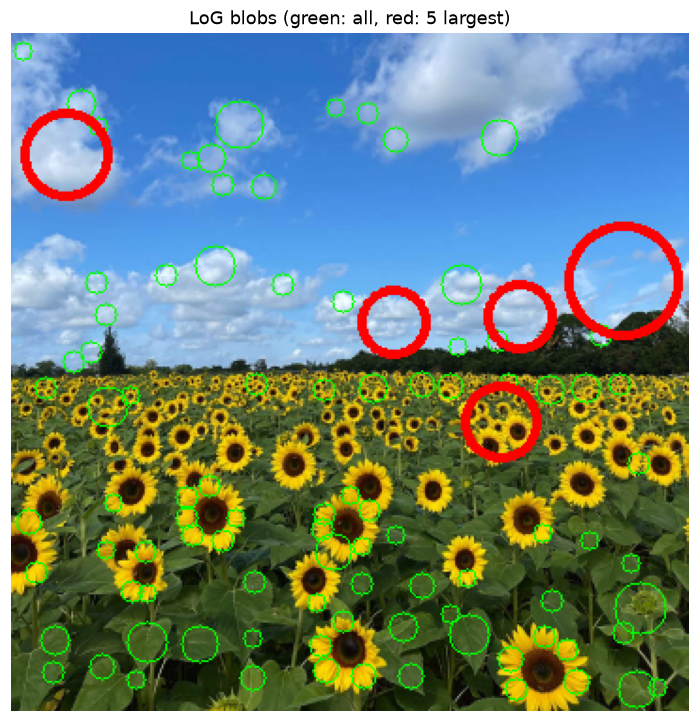

Largest circles:
 #      x      y   sigma   radius=sqrt2*sigma  response
 1    325    131   20.23                28.61     0.136
 2     29     64   15.40                21.78     0.144
 3    260    206   13.44                19.01     0.109
 4    270    150   11.73                16.58     0.181
 5    203    153   11.73                16.58     0.134


In [10]:
# draw all circles, highlight the 5 largest
largest = sorted(blobs, key=lambda b: -b[3])[:5]
out = im.copy()
for x, y, s, r, _ in blobs:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 255, 0), 1)
for x, y, s, r, _ in largest:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 0, 255), 3)
show(out, "LoG blobs (green: all, red: 5 largest)", (11, 8))

print("Largest circles:")
print(f"{'#':>2} {'x':>6} {'y':>6} {'sigma':>7} {'radius=sqrt2*sigma':>20} {'response':>9}")
for i, (x, y, s, r, resp) in enumerate(largest, 1):
    print(f"{i:>2} {x:>6.0f} {y:>6.0f} {s:>7.2f} {r:>20.2f} {resp:>9.3f}")


### Q1 – Discussion (fill in with your numbers)
* **σ range:** the cell above prints it (default 3 → 40, i.e. radii ≈ 4.2 → 56.6 px on the ¼-size image). The lower bound is set by the
  smallest sunflower head visible in the reduced image, the upper bound by the biggest head; make sure the largest circle is **not** at the last scale
  (extrema on the boundary scales are discarded, so widen `SIGMA_MAX` if the biggest blob disappears).
* **Largest circles:** report the table of (x, y, σ, r) printed above.
* **Parameters that matter:** `THRESH` trades missed flow### Q1 – Discussion

**σ range used:** σ ∈ [3, 40], 20 scales, geometric spacing (k = 1.146). This corresponds to radii r = √2·σ ∈ [4.2, 56.6] px on the ¼-size image (360×360).

**Blobs detected:** 96 after thresholding (0.05 on the scale-normalised response), 3-D non-maximum suppression, overlap pruning and removal of blobs whose circle falls mostly outside the image.

**Largest circles (x, y, σ, r = √2σ):**

| # | x | y | σ | r (px) | response |
|---|---|---|---|---|---|
| 1 | 325 | 131 | 20.23 | 28.61 | 0.136 |
| 2 | 29 | 64 | 15.40 | 21.78 | 0.144 |
| 3 | 260 | 206 | 13.44 | 19.01 | 0.109 |
| 4 | 270 | 150 | 11.73 | 16.58 | 0.181 |
| 5 | 203 | 153 | 11.73 | 16.58 | 0.134 |

The largest circle has σ = 20.23 and r ≈ 28.6 px, centred at (325, 131).

**Border artifacts.** Before filtering, the three largest detections (σ = 34.9, 26.6 and 20.2) were centred within 2 px of the image edge, so most of each circle lay outside the image. Their response came from the boundary handling of the Gaussian/Laplacian (replicated border pixels look like one large bright or dark region at high σ), not from a sunflower head. Discarding blobs with more than 50% of their radius outside the image removed these and 15 other border detections.

**Adequacy of the σ range.** The largest valid blob is at σ ≈ 20, well inside [3, 40], and the detected scales span σ ≈ 11.7–20.2. Since extrema at the first and last scale are discarded, the fact that no valid blob sits near σ = 40 shows the upper bound is not truncating real flowers. The lower bound of 3 (r ≈ 4 px) is below the smallest visible head, so small heads are covered.

**Response vs. size.** The strongest response among the top five is #4 (0.181, σ = 11.7), not the largest circle. The scale-normalised response depends on contrast as well as scale, so a smaller, high-contrast head can outrank a larger, lower-contrast one. Radius, not response, is therefore used to rank "largest" here. Circles #4 and #5 share σ = 11.73 and are 67 px apart (about 2 radii), which suggests neighbouring heads of similar size, since the pruning step only suppresses overlapping circles.

**Effect of the parameters.**
* `THRESH` trades missed flowers against false blobs on leaves, shadows and texture. Detections with low response (near 0.05) are mostly texture; the strong ones are the reliable heads.
* Geometric σ spacing keeps relative scale resolution constant (each step changes the radius by 14.6%).
* 3-D non-maximum suppression assigns each blob its characteristic scale instead of reporting it at every scale where it responds; overlap pruning keeps only the stronger of two overlapping circles.

**Limitations.** LoG responds to any roughly circular bright region, so bright sky, highlights, and tilted, overlapping or occluded heads can give wrong centres or radii. Partially visible heads at the image border are removed, so flowers cut off by the frame are not reported.ers vs. false blobs on texture (leaves, shadows); geometric σ spacing keeps relative scale
  resolution constant; the 3-D NMS ensures each blob is reported at its characteristic scale rather than at every scale where it responds.
* **Limitations:** LoG responds to any bright, roughly circular region, so bright sky/patches or tilted/occluded heads can give wrong radii; overlapping heads are merged by the pruning step.

---
# Q2 – RANSAC line and circle fitting

First we generate the noisy point set from Listing 1 (100 points: 50 on a noisy circle centre (2,3), r=10, radial σ = r/16 = 0.625; 50 on a noisy line y = −x + 2 with σ = 1).

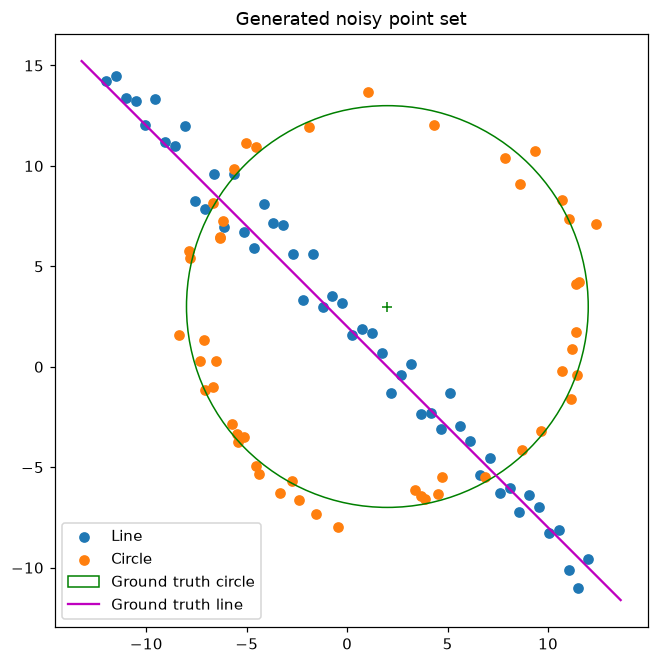

In [11]:
np.random.seed(0)           # comment out for a different random set each run
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color="g", fill=False, label="Ground truth circle"))
ax.plot(x0_gt, y0_gt, "+", color="g")
x_ = np.array(ax.get_xlim()); ax.plot(x_, m * x_ + b, color="m", label="Ground truth line")
ax.set_aspect("equal"); ax.legend(); ax.set_title("Generated noisy point set"); plt.show()